# 07 - Final model comparison (all 8 models)
**Protocol**
1. Every model is fitted on the **training** set and scored on the **validation** set -> used to pick the best model and the hybrid weight.
2. Every model is **refitted on train + validation** and scored **once** on the untouched **test** set -> the numbers reported in the report and dashboard. Training time of this refit and a **5-fold cross-validation** on train + validation are recorded too.

The code for this protocol is `src/train_models.py` (run below). It saves `models/*.pkl`, `outputs/model_comparison.csv` and the supporting metric files used by the dashboard.


In [2]:
import sys, warnings
sys.path.append("..")                      # lets the notebook import the reusable code in ../src
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from src import config, preprocess as P, models as M
from src.evaluate import regression_metrics, permutation_table
sns.set_theme(style="whitegrid")
pd.options.display.float_format = "{:,.2f}".format
config.PLOT_DIR.mkdir(parents=True, exist_ok=True)

## 1. Run the full protocol
The full training pipeline is executed using the reusable training module. It trains and evaluates all models according to the defined protocol. Five-fold cross-validation is enabled to provide additional information about model performance. The trained models and evaluation results are saved for later use in the dashboard and report.

In [3]:
from src import train_models
test_df = train_models.main(cv=True)

train/val/test = 3102/665/665 rows
models: ridge, random_forest, extra_trees, xgboost, lightgbm, catboost, stacking, hybrid
hybrid: best RF weight on validation = 0.8
  validation Ridge Regression (baseline): MAE=21,230  (0.8s)
  validation Random Forest (Bagging): MAE=17,140  (1.4s)
  validation Extra Trees (Bagging): MAE=18,630  (1.9s)
  validation XGBoost (Boosting): MAE=24,287  (1.2s)
  validation LightGBM (Boosting): MAE=21,888  (3.1s)
  validation CatBoost (Boosting): MAE=24,380  (3.4s)
  validation Stacking (Ridge meta-model): MAE=17,898  (52.7s)
  validation Hybrid (RF + ANN): MAE=16,874  (4.1s)
  test Ridge Regression (baseline): MAE=20,211 R2=0.787 time=1.0s CV_MAE=21,411±1,810
  test Random Forest (Bagging): MAE=16,347 R2=0.850 time=1.8s CV_MAE=17,649±843
  test Extra Trees (Bagging): MAE=17,816 R2=0.844 time=2.2s CV_MAE=19,025±1,099
  test XGBoost (Boosting): MAE=23,757 R2=0.806 time=1.8s CV_MAE=24,457±1,739
  test LightGBM (Boosting): MAE=20,021 R2=0.840 time=3.2s CV_MAE=2

In [4]:
from src.evaluate import mark_best
val_df = pd.read_csv(config.OUT_DIR / "validation_comparison.csv")
test_df = pd.read_csv(config.OUT_DIR / "model_comparison.csv")
gap = pd.read_csv(config.METRIC_DIR / "overfitting_gap.csv")
best_val = (config.OUT_DIR / "best_model.txt").read_text()
print("VALIDATION (used to choose the model)"); display(val_df) if "display" in globals() else print(val_df)
print("TEST (final result)  - trophy = lowest test MAE, tick = chosen on validation")
final_table = mark_best(test_df, best_val)
display(final_table) if "display" in globals() else print(final_table)

VALIDATION (used to choose the model)
                         Model       MAE      RMSE   R2  MAPE_%  MedianAE  \
0  Ridge Regression (baseline) 21,229.87 42,128.03 0.81   32.61  9,608.32   
1      Random Forest (Bagging) 17,139.68 33,975.96 0.87   29.43  8,361.19   
2        Extra Trees (Bagging) 18,630.32 35,504.95 0.86   33.15  9,842.23   
3           XGBoost (Boosting) 24,286.86 42,934.85 0.80   37.18 13,455.70   
4          LightGBM (Boosting) 21,887.53 40,909.24 0.82   38.51 10,794.10   
5          CatBoost (Boosting) 24,380.32 43,230.72 0.80   37.06 13,182.03   
6  Stacking (Ridge meta-model) 17,898.16 34,494.32 0.87   30.43  9,026.39   
7            Hybrid (RF + ANN) 16,873.99 33,457.36 0.88   29.37  8,017.64   

   Train_time_s  
0          0.80  
1          1.36  
2          1.89  
3          1.21  
4          3.06  
5          3.41  
6         52.73  
7          4.13  
TEST (final result)  - trophy = lowest test MAE, tick = chosen on validation
                             

## 2. Metric comparison charts (test set)
compares the eight models using six evaluation measures: MAE, RMSE, R², MAPE, training time and cross-validation MAE. The charts help identify the models with better prediction accuracy and training efficiency. Lower MAE, RMSE and MAPE values are preferred, while higher R² is better.

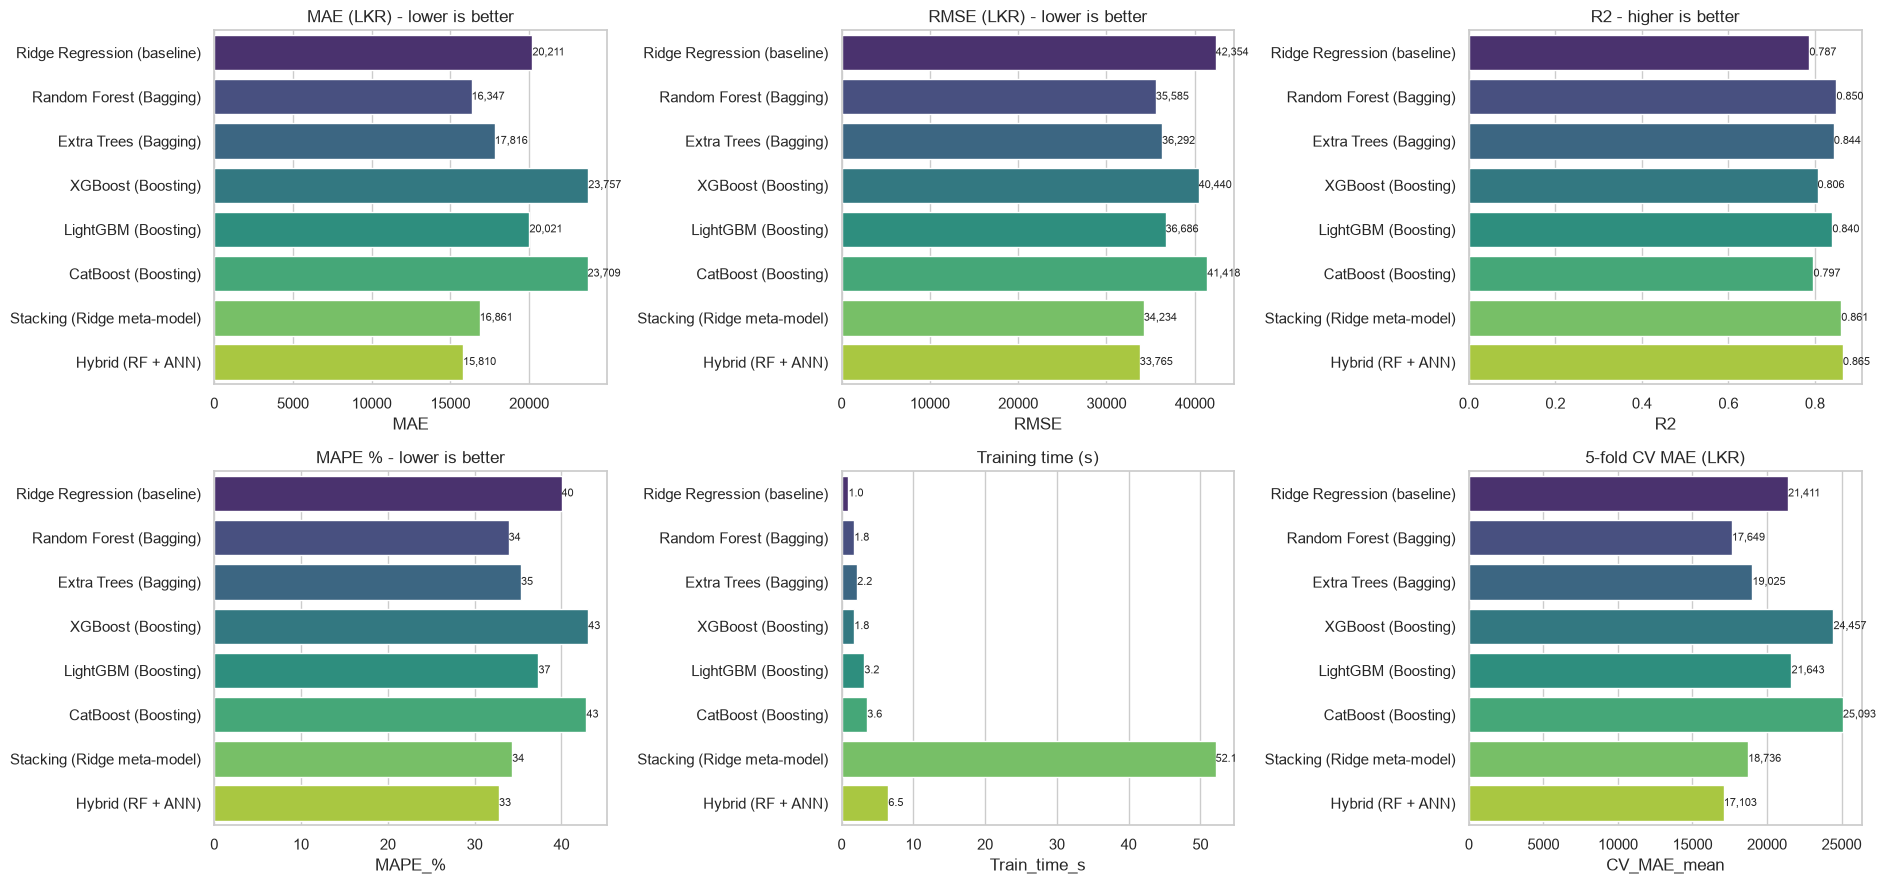

In [5]:
metrics = [("MAE", "MAE (LKR) - lower is better"), ("RMSE", "RMSE (LKR) - lower is better"), ("R2", "R2 - higher is better"),
           ("MAPE_%", "MAPE % - lower is better"), ("Train_time_s", "Training time (s)"), ("CV_MAE_mean", "5-fold CV MAE (LKR)")]
metrics = [m for m in metrics if m[0] in test_df.columns]
fig, ax = plt.subplots(2, 3, figsize=(19, 9))
for a, (col, title) in zip(ax.ravel(), metrics):
    sns.barplot(data=test_df, x=col, y="Model", ax=a, palette="viridis")
    a.set_title(title); a.set_ylabel("")
    for p in a.patches:
        w = p.get_width(); a.annotate(f"{w:,.3f}" if col == "R2" else f"{w:,.1f}" if col == "Train_time_s" else f"{w:,.0f}",
                                       (w, p.get_y() + p.get_height() / 2), ha="left", va="center", fontsize=8)
plt.tight_layout(); plt.savefig(config.PLOT_DIR / "07_metric_comparison.png", dpi=150); plt.show()

## 3. Actual vs predicted and residuals (all models)

Actual and predicted prices are compared for all eight models using scatter plots. Predictions closer to the reference line indicate better accuracy. Residual distributions are also examined to understand whether models tend to overpredict or underpredict phone prices.

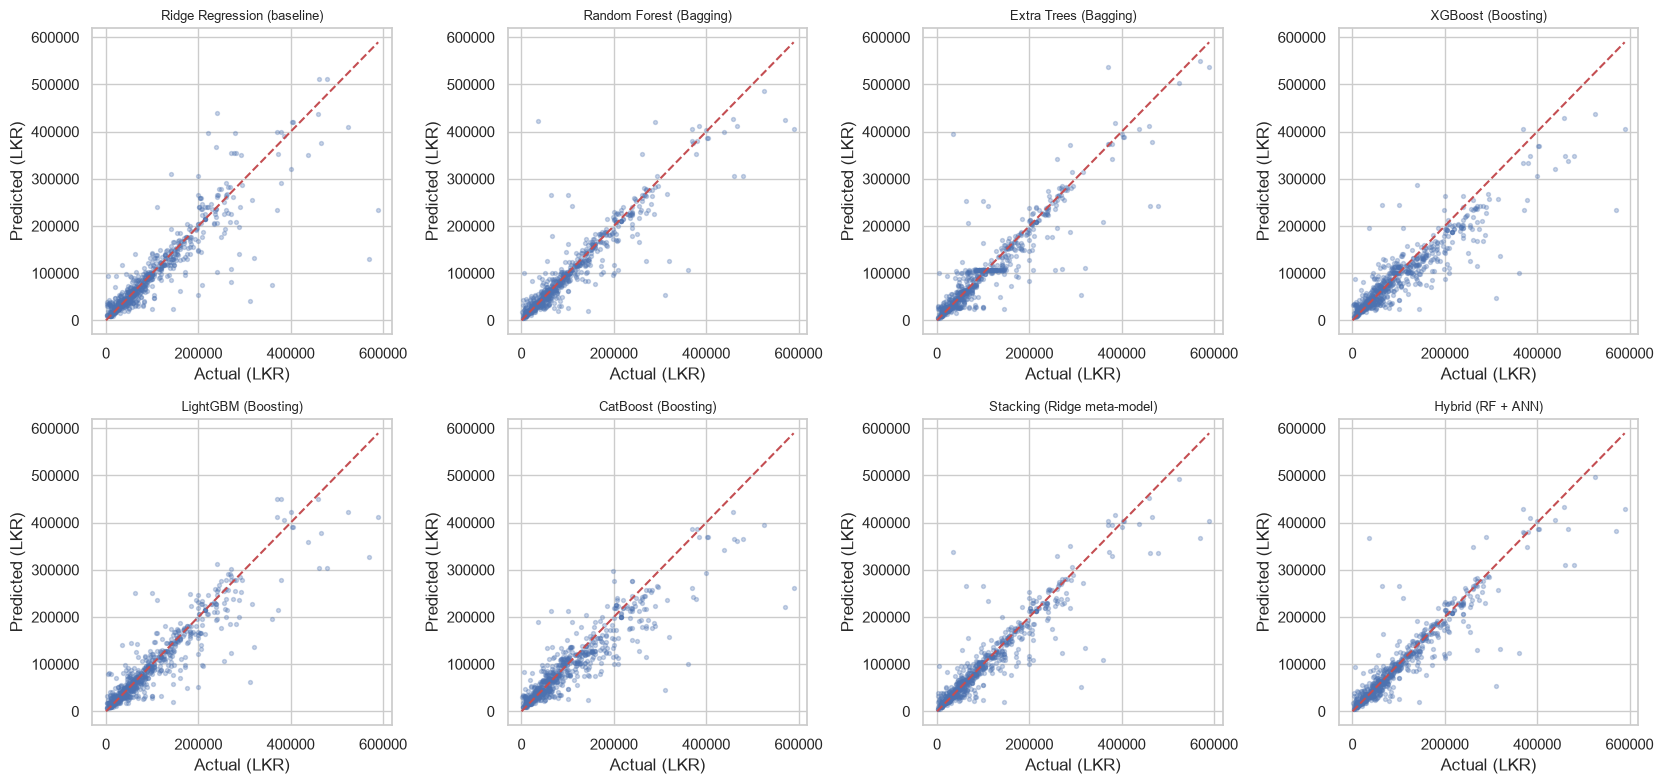

In [6]:
preds = pd.read_csv(config.OUT_DIR / "test_predictions.csv")
models_ = list(test_df["Model"])
ncols = 4; nrows = int(np.ceil(len(models_) / ncols))
fig, ax = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 4 * nrows))
for a, m in zip(ax.ravel(), models_):
    a.scatter(preds["price"], preds[m], alpha=.3, s=8); lim = [0, preds[["price", m]].max().max()]
    a.plot(lim, lim, "r--"); a.set_title(m, fontsize=9); a.set_xlabel("Actual (LKR)"); a.set_ylabel("Predicted (LKR)")
for a in ax.ravel()[len(models_):]: a.axis("off")
plt.tight_layout(); plt.savefig(config.PLOT_DIR / "07_actual_vs_predicted.png", dpi=150); plt.show()

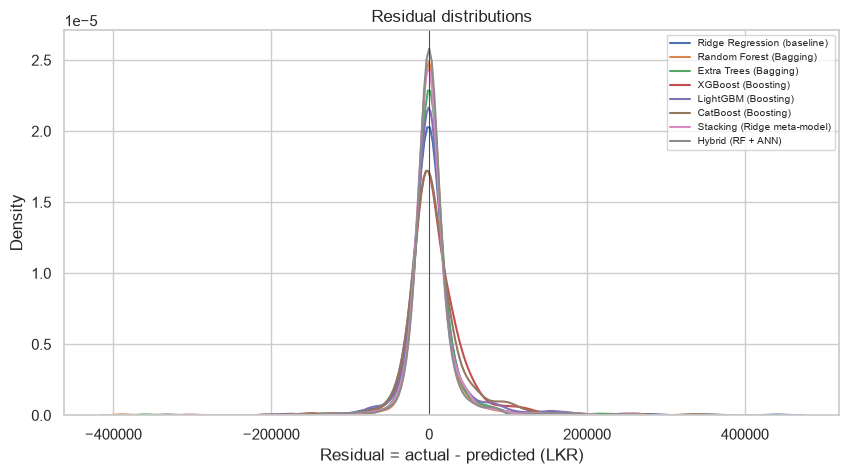

In [7]:
plt.figure(figsize=(10, 5))
for m in models_:
    sns.kdeplot(preds["price"] - preds[m], label=m)
plt.axvline(0, c="k", lw=.5); plt.xlabel("Residual = actual - predicted (LKR)"); plt.legend(fontsize=7); plt.title("Residual distributions")
plt.savefig(config.PLOT_DIR / "07_residuals.png", dpi=150); plt.show()

## 4. Where does each model make its errors? 
analyses model errors across different data sources and phone conditions. It helps identify whether models perform differently for each group. However, the Dialog dataset contains fewer records than ikman, so its results should be interpreted carefully because of the smaller sample size.

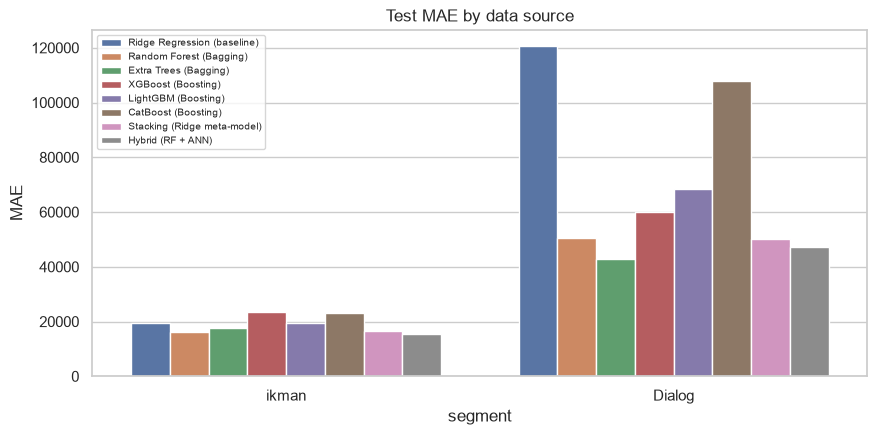

segment,Dialog,ikman
Model,,
CatBoost (Boosting),"107,900.24","22,942.94"
Extra Trees (Bagging),"43,015.55","17,586.54"
Hybrid (RF + ANN),"47,073.44","15,524.97"
LightGBM (Boosting),"68,502.47","19,579.43"
Random Forest (Bagging),"50,636.95","16,034.57"
Ridge Regression (baseline),"120,539.97","19,297.04"
Stacking (Ridge meta-model),"50,248.45","16,557.09"
XGBoost (Boosting),"59,997.96","23,427.03"


In [8]:
seg = pd.read_csv(config.METRIC_DIR / "error_by_segment.csv")
seg_src = seg[seg["segment_by"] == "source"]
plt.figure(figsize=(10, 4.5))
sns.barplot(data=seg_src, x="segment", y="MAE", hue="Model"); plt.title("Test MAE by data source"); plt.legend(fontsize=7)
plt.savefig(config.PLOT_DIR / "07_mae_by_source.png", dpi=150); plt.show()
seg_src.pivot(index="Model", columns="segment", values="MAE")

In [9]:
seg[seg["segment_by"] == "condition"].pivot(index="Model", columns="segment", values="MAE")

segment,Brand New,Used
Model,,
CatBoost (Boosting),"33,066.39","20,419.34"
Extra Trees (Bagging),"22,237.75","16,261.17"
Hybrid (RF + ANN),"22,085.34","13,602.91"
LightGBM (Boosting),"32,299.25","15,703.43"
Random Forest (Bagging),"23,329.01","13,891.63"
Ridge Regression (baseline),"30,315.37","16,657.38"
Stacking (Ridge meta-model),"24,017.59","14,344.66"
XGBoost (Boosting),"32,202.63","20,787.28"


In [10]:
print(seg_src.groupby("segment")["rows"].first())

segment
Dialog      6
ikman     659
Name: rows, dtype: int64


Dialog rows are far fewer than ikman rows, so Dialog-specific errors are based on a small sample.

## 5. Over-fitting check: train vs test R2
Training and test R² values are compared to identify possible overfitting. A large difference between these values may indicate that a model does not generalise well to unseen data. Cross-validation results are also considered to understand the consistency of model performance.

In [11]:
gap

,Model,R2_train,R2_test,R2_gap,MAE_train,MAE_test
0,Ridge Regression (baseline),0.80,0.79,0.01,"18,690.25","20,210.51"
1,Random Forest (Bagging),0.90,0.85,0.05,"12,057.56","16,346.77"
2,Extra Trees (Bagging),0.91,0.84,0.07,"11,920.61","17,815.98"
3,XGBoost (Boosting),0.82,0.81,0.01,"22,746.43","23,756.99"
4,LightGBM (Boosting),0.84,0.84,-0.00,"18,360.46","20,020.84"
5,CatBoost (Boosting),0.79,0.80,-0.00,"23,354.49","23,709.47"
6,Stacking (Ridge meta-model),0.89,0.86,0.03,"13,695.04","16,861.08"
7,Hybrid (RF + ANN),0.91,0.86,0.04,"11,690.97","15,809.62"


## 6. Feature importance
Feature importance is used to understand which input features contribute to model predictions. Permutation importance measures how much the test MAE increases when a feature is shuffled. A larger increase indicates that the feature has a stronger effect on the model's predictive performance.

In [12]:
imp = pd.read_csv(config.METRIC_DIR / "feature_importance.csv")
imp.pivot(index="feature", columns="Model", values="importance_%").round(1)

Model,CatBoost (Boosting),Extra Trees (Bagging),LightGBM (Boosting),Random Forest (Bagging),XGBoost (Boosting)
feature,,,,,
brand,44.60,32.40,23.60,34.80,31.30
condition,10.20,11.70,4.70,9.90,4.60
location,1.10,3.10,20.90,3.60,2.70
model,23.40,33.50,31.40,31.90,56.90
ram_gb,8.10,8.40,7.40,13.50,2.30
source,0.30,0.40,0.80,0.20,0.80
storage_gb,12.30,10.40,11.10,6.00,1.40


permutation importance of the validation-chosen model: Hybrid (RF + ANN)


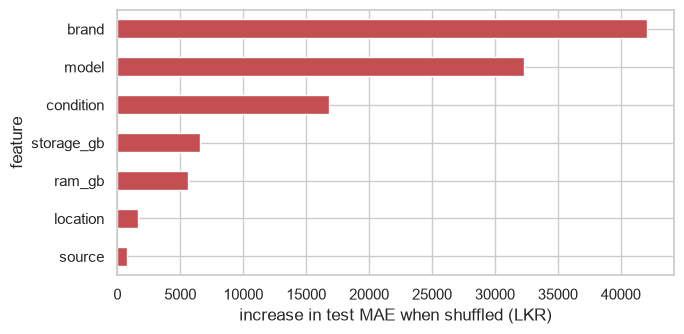

In [13]:
pi = pd.read_csv(config.METRIC_DIR / "permutation_importance_best.csv")
print("permutation importance of the validation-chosen model:", best_val)
pi.sort_values("mae_increase").plot.barh(x="feature", y="mae_increase", legend=False, figsize=(7, 3.5), color="#C44E52")
plt.xlabel("increase in test MAE when shuffled (LKR)"); plt.tight_layout()
plt.savefig(config.PLOT_DIR / "07_permutation_importance.png", dpi=150); plt.show()

## 7. Hybrid weight experiment (validation)
The hybrid weight search results are loaded to review the different Random Forest and ANN weight combinations. The selected combination is based on the lowest validation MAE, not the test results.

In [14]:
pd.read_csv(config.METRIC_DIR / "hybrid_weight_search.csv")

,rf_weight,ann_weight,val_MAE,val_RMSE,val_R2
0,0.10,0.90,"18,657.96","36,261.43",0.86
1,0.20,0.80,"18,193.92","35,449.79",0.86
2,0.30,0.70,"17,786.04","34,764.58",0.87
3,0.40,0.60,"17,443.44","34,213.39",0.87
4,0.50,0.50,"17,177.04","33,802.78",0.88
5,0.60,0.40,"16,994.86","33,537.91",0.88
6,0.70,0.30,"16,887.84","33,422.26",0.88
7,0.80,0.20,"16,873.99","33,457.36",0.88
8,0.90,0.10,"16,928.11","33,642.75",0.88


## 8. Key findings (computed from the results)

In [15]:
from src.evaluate import key_findings
for line in key_findings(test_df, val_df, gap):
    print("-", line)

- Best model on the untouched test set: **Hybrid (RF + ANN)** (MAE Rs. 15,810, RMSE Rs. 33,765, R² 0.865).
- Weakest model: **XGBoost (Boosting)** (MAE Rs. 23,757); the best model's MAE is 33.5% lower.
- The best ensemble cuts the MAE of the Ridge baseline by 21.8%.
- Random Forest vs gradient boosting: best booster is **LightGBM (Boosting)** (MAE 22.5% higher than Random Forest); training time RF 1.8s vs 3.2s.
- Stacking vs its best single model: MAE did not improve by 3.1%.
- Hybrid RF + ANN vs Random Forest alone: MAE 3.3% lower.
- Largest train-to-test R² gap (a sign of over-fitting): **Extra Trees (Bagging)** (0.069).


## 9. Interpretation

- **Best model:** Hybrid (RF + ANN) achieved the lowest test MAE (Rs. 15,810) and R² of 0.865, improving MAE by 22% over Ridge.
- **Random Forest vs Boosting:** Random Forest outperformed all three boosting models, although further tuning may improve boosting performance.
- **Stacking and Hybrid:** Hybrid performed slightly better than Random Forest. Stacking did not improve MAE because the base models made similar errors.
- **Over-fitting:** Random Forest and Hybrid showed relatively small training-test gaps. Some boosting models were under-fitted rather than over-fitted.
- **Cost vs Accuracy:** Hybrid achieved the best accuracy in 6.5 seconds, while Random Forest was almost equally accurate and much faster. Stacking took 52 seconds without improving MAE.
- **Model weaknesses:** Predictions were less accurate for Brand New phones. Dialog results were unreliable due to the very small test sample.
- **Limitations:** The dataset contains asking prices rather than actual selling prices, missing RAM values, mixed data sources and some potentially incorrect prices. Results may change with further tuning and newer data.